# Chơi thử Ms. Pacman

Notebook này dựng đúng môi trường `ALE/MsPacman-v5` mà agent PPO/DQN trong `pacman_rl` dùng, để bạn tự chơi bằng bàn phím và cảm nhận độ khó trước khi xem agent học.

**Điều khiển** (cửa sổ game mở bằng pygame):

| Phím | Hành động |
|---|---|
| `↑ ↓ ← →` hoặc `W A S D` | Di chuyển |
| Giữ hai phím (vd `↑` + `→`) | Hướng chéo (action set của Ms. Pacman có 8 hướng) |
| `P` | Tạm dừng / tiếp tục |
| `R` | Chơi lại từ đầu |
| `Esc` hoặc đóng cửa sổ | Thoát |

Chạy các ô theo thứ tự. Cửa sổ game mở **ngoài** notebook nên cần chạy Jupyter/VS Code trên máy của bạn (không dùng được trên Colab hay server không có màn hình).

## 1. Cài thư viện
Chỉ cần chạy một lần. Bản phiên bản khớp với `requirements-venv.txt` của project (Python 3.10, `numpy<2`).

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {
    "gymnasium": "gymnasium==0.29.1",
    "ale_py": "ale-py>=0.9.0,<0.11.0",   # đã kèm ROM Atari, không cần AutoROM
    "pygame": "pygame",
    "numpy": "numpy<2",
    "matplotlib": "matplotlib",
    "cv2": "opencv-python",           # AtariPreprocessing cần (chỉ dùng ở mục 5)
}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Đang cài:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Xong. Nếu import bên dưới báo lỗi thì restart kernel rồi chạy lại.")
else:
    print("Đủ thư viện.")

Đủ thư viện.


## 2. Tạo môi trường
Dùng `frameskip=1` và `repeat_action_probability=0` để game chạy đúng 60 FPS và nhận phím tức thì (khác với lúc train agent, vốn bỏ qua 4 frame mỗi bước).

Env        : ALE/MsPacman-v5
Hành động  : {0: 'NOOP', 1: 'UP', 2: 'RIGHT', 3: 'LEFT', 4: 'DOWN', 5: 'UPRIGHT', 6: 'UPLEFT', 7: 'DOWNRIGHT', 8: 'DOWNLEFT'}
Khung hình : (210, 160, 3) | số mạng: 3


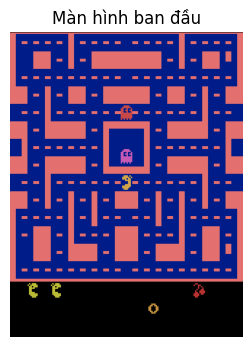

In [2]:
import os
import gymnasium as gym
import ale_py
import numpy as np
import matplotlib.pyplot as plt

gym.register_envs(ale_py) if hasattr(gym, "register_envs") else None

ENV_ID = "ALE/MsPacman-v5"


def make_play_env():
    return gym.make(ENV_ID, frameskip=1, repeat_action_probability=0.0,
                    full_action_space=False, render_mode="rgb_array")


env = make_play_env()
meanings = env.unwrapped.get_action_meanings()
obs, info = env.reset(seed=0)
frame = env.render()

print("Env        :", ENV_ID)
print("Hành động  :", dict(enumerate(meanings)))
print("Khung hình :", frame.shape, "| số mạng:", info.get("lives"))
plt.figure(figsize=(3, 4)); plt.imshow(frame); plt.axis("off"); plt.title("Màn hình ban đầu"); plt.show()

## 3. Hàm chơi
Hàm `play()` đọc phím, đổi thành action của ALE và hiển thị từng frame. Điểm và số mạng hiện ở thanh tiêu đề cửa sổ.

In [3]:
import time
import pygame

# (lên, xuống, trái, phải) -> tên action của ALE
_DIR_TO_ACTION = {
    (0, 0, 0, 0): "NOOP",
    (1, 0, 0, 0): "UP",       (0, 1, 0, 0): "DOWN",
    (0, 0, 1, 0): "LEFT",     (0, 0, 0, 1): "RIGHT",
    (1, 0, 1, 0): "UPLEFT",   (1, 0, 0, 1): "UPRIGHT",
    (0, 1, 1, 0): "DOWNLEFT", (0, 1, 0, 1): "DOWNRIGHT",
}
_KEYS = {
    "up": (pygame.K_UP, pygame.K_w), "down": (pygame.K_DOWN, pygame.K_s),
    "left": (pygame.K_LEFT, pygame.K_a), "right": (pygame.K_RIGHT, pygame.K_d),
}


def _read_action(pressed, name_to_id):
    # Nhấn đồng thời hai hướng đối nhau (↑+↓) thì triệt tiêu về 0
    u, d, l, r = (int(any(pressed[k] for k in _KEYS[n])) for n in ("up", "down", "left", "right"))
    if u and d: u = d = 0
    if l and r: l = r = 0
    return name_to_id[_DIR_TO_ACTION[(u, d, l, r)]]


def play(scale=3, fps=60, seed=None, max_frames=None, auto_restart=False):
    """Chơi Ms. Pacman bằng bàn phím. Trả về danh sách điểm của các ván đã chơi xong.

    scale        : phóng to khung 160x210 bao nhiêu lần.
    fps          : tốc độ game (60 là tốc độ gốc của Atari; giảm xuống 30 nếu thấy khó).
    max_frames   : dừng sau chừng này frame (dùng để test), None = chơi đến khi thoát.
    auto_restart : True thì hết mạng tự chơi ván mới thay vì chờ bấm R.
    """
    env = make_play_env()
    name_to_id = {n: i for i, n in enumerate(env.unwrapped.get_action_meanings())}
    pygame.init()
    h, w = env.observation_space.shape[:2]
    screen = pygame.display.set_mode((w * scale, h * scale))
    clock = pygame.time.Clock()
    font = pygame.font.SysFont(None, 28)

    env.reset(seed=seed)
    score, lives, paused, game_over, frames = 0.0, None, False, False, 0
    scores = []
    running = True
    try:
        while running:
            for e in pygame.event.get():
                if e.type == pygame.QUIT:
                    running = False
                elif e.type == pygame.KEYDOWN:
                    if e.key == pygame.K_ESCAPE:
                        running = False
                    elif e.key == pygame.K_p:
                        paused = not paused
                    elif e.key == pygame.K_r or (game_over and e.key == pygame.K_RETURN):
                        env.reset(); score, game_over = 0.0, False

            if not paused and not game_over:
                action = _read_action(pygame.key.get_pressed(), name_to_id)
                _, r, terminated, truncated, info = env.step(action)
                score += r
                lives = info.get("lives", lives)
                frames += 1
                if terminated or truncated:
                    scores.append(score)
                    print(f"Ván {len(scores)}: {score:.0f} điểm")
                    if auto_restart:
                        env.reset(); score = 0.0
                    else:
                        game_over = True

            frame = env.render()
            surf = pygame.surfarray.make_surface(frame.swapaxes(0, 1))
            screen.blit(pygame.transform.scale(surf, screen.get_size()), (0, 0))
            if paused or game_over:
                msg = "TẠM DỪNG - bấm P" if paused else f"HẾT GAME: {score:.0f} - bấm R"
                txt = font.render(msg, True, (255, 255, 0), (0, 0, 0))
                screen.blit(txt, txt.get_rect(center=(w * scale // 2, h * scale // 2)))
            pygame.display.flip()
            pygame.display.set_caption(f"Ms. Pacman | điểm {score:.0f} | mạng {lives}")
            clock.tick(fps)

            if max_frames is not None and frames >= max_frames:
                break
    finally:
        pygame.quit()
        env.close()
    return scores

## 4. Chơi
Chạy ô dưới, cửa sổ game sẽ hiện lên (có thể nằm sau cửa sổ VS Code/trình duyệt). Click vào cửa sổ game để nó nhận phím. Thoát bằng `Esc`.

In [4]:
scores = play(scale=3, fps=60)
print("Điểm các ván:", scores)

Điểm các ván: []


## 5. Tham khảo: agent nhìn thấy gì
Agent không thấy màn hình đầy đủ như bạn. Pipeline tiền xử lý là: bỏ qua 4 frame, thu về ảnh xám 84×84, xếp 4 frame gần nhất. Ô dưới vẽ lại để bạn so sánh (không cần cài `pacman_rl`, chỉ dùng wrapper có sẵn của gymnasium).

In [ ]:
def make_agent_view_env(rgb=False):
    e = gym.make(ENV_ID, frameskip=1, repeat_action_probability=0.0,
                 full_action_space=False)
    e = gym.wrappers.AtariPreprocessing(e, noop_max=30, frame_skip=4, screen_size=84,
                                        terminal_on_life_loss=False, grayscale_obs=not rgb,
                                        scale_obs=False)
    return gym.wrappers.FrameStack(e, 4)


agent_env = make_agent_view_env(rgb=False)
obs, _ = agent_env.reset(seed=0)
for _ in range(120):   # chạy ngẫu nhiên một lúc để qua màn mở đầu
    obs, *_ = agent_env.step(agent_env.action_space.sample())
obs = np.asarray(obs)  # (4, 84, 84)

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(obs[i], cmap="gray"); ax.axis("off"); ax.set_title(f"frame t-{3 - i}")
plt.suptitle("Quan sát của agent: 4 frame xám 84x84"); plt.show()
agent_env.close()